# Li et al. 2019 — Melanoma · Step 04 · EMT-TF expression

The unconditional EMT-TF step (last notebook; Gate 3 = NA / non-branching, so numbered 04). Score a
mesenchymal-TF panel (Snail/Zeb/Twist plus FOXC and PRRX families, per the Kürten lesson) gated on
detectable expression, pick the two most pseudotime-directional expressed factors, and overlay
thresholded expressers on the grey manifold (categorical overlay, house orientation).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 1082 | pseudotime 0.0 -> 20.93


### Derive the EMT-TF pair — detection-gated, pseudotime-directional

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round(float((x>0).mean()),3), round(float(x[early].mean()),3),
                 round(float(x[late].mean()),3), round(float(rho),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus); {len(ok)} TFs pass 3% detection')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.048       0.014      0.004    -0.085    EARLY(root)
 PRRX2      0.031       0.006      0.004    -0.051    EARLY(root)
TWIST1      0.032       0.008      0.004    -0.045    EARLY(root)
  ZEB2      0.430       0.140      0.128    -0.035    EARLY(root)
  ZEB1      0.033       0.010      0.007    -0.019    EARLY(root)
 SNAI2      0.274       0.100      0.087    -0.005    EARLY(root)
 PRRX1      0.155       0.046      0.037     0.019    EARLY(root)
 SNAI1      0.006       0.000      0.002     0.046 LATE(terminus)

derived pair: FOXC1 (early/root) <-> PRRX1 (late/terminus); 7 TFs pass 3% detection


### Deliverable — EMT-TF overlay (categorical, house `(3.5,1.5)`)

Thresholded expressers (upper quartile among expressing cells) of the two derived TFs overlaid on
the grey manifold, matching the reference plotting style.

FOXC1: 4.8% expressing; 13 shown (upper quartile), mean pseudotime 0.25
PRRX1: 15.5% expressing; 42 shown (upper quartile), mean pseudotime 0.45
saved expression.pdf


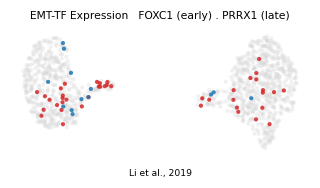

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.10
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7)
ax.text(.5,-.16,'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), mean pseudotime {tn[m].mean():.2f}')
print('saved expression.pdf')